# PPKS 02: Uzorkovanje signala i analiza preklapanja spektra


## Aliasing - preklapanje spektra

Na prvom predavanju smo rekli da prema __Nyquist-Shannonovom teoremu uzorkovanja__, frekvencija uzorkovanja $f_s$ mora biti barem dvostruko veća od najveće frekvencije u signalu ($f_{max}$) kako bi se izbjegao aliasing (gubitak informacija zbog nedovoljnog uzorkovanja). Dakle, ako signal $x(t)$ sadrži samo frekvencije do $f_{max}$, tada frekvencija uzorkovanja mora biti:

$f_{s}\ge2f_{max}$

Ali zašto je to tako?

Definicija: __Aliasing__ ili preklapanje spektra je pojava pri uzorkovanju koja nastaje kada je frekvencija uzorkovanja manja od dopuštene prema Nyquist–Shannonovom teoremu. Tada dolazi do preklapanja spektralnih komponenti signala pri čemu se visokofrekventne komponente preslikavaju u niže frekvencije, što uzrokuje gubitak informacije o originalnom signalu.

Za frekvenciju uzorkovanja $f_s$, frekvencije $f$ i $f'$ su aliasi ako postoji $k \in \mathbb{Z}$ za koji vrijedi

$f'=f+k\cdot f_s$

Dakle, ako se uzorkuju frekvencijom $f_s$, kontinuirane sinusoide $x(t)$ frekvencije $f$ i $y(t)$ frekvencije $f'$:

$x[n]=Acos(2\pi f \frac{n}{f_s}+\Phi$)

$y[n]=Acos(2\pi f' \frac{n}{f_s}+\Phi$)

u slučaju gornje jednakosti će dati isti diskretni signal $x[n] = y[n]$. To se može vidjeti na primjeru u nastavku, gdje su dva kosinusna signala frekvencija $f_1= 1 \text{ Hz}$ i $f_2= 9 \text{ Hz}$  uzorkovani frekvencijom uzorkovanja $f_s= 8 \text{ Hz}$ pa daju iste diskretne signale.

***

__Dokaz__: Pretpostavimo da su frekvencije $f$ i $f'$ povezane relacijom

$f' = f + k\cdot f_s$

gdje je $k \in \mathbb{Z}$.

Diskretni signal dobiven uzorkovanjem sinusoide frekvencije $f$ je
$x[n]=Acos\left(2\pi f \frac{n}{f_s}+\Phi\right)$, a signal frekvencije $f'$ je $y[n]=Acos\left(2\pi f' \frac{n}{f_s}+\Phi\right)$.

Uvrstimo relaciju $f' = f + k f_s$ u izraz za $y[n]$:

$y[n]=Acos\left(2\pi (f+kf_s)\frac{n}{f_s}+\Phi\right)$

Razdvojimo članove:

$y[n]=Acos\left(2\pi f\frac{n}{f_s}+2\pi k f_s\frac{n}{f_s}+\Phi\right)$, odnosno:
$y[n]=Acos\left(2\pi f\frac{n}{f_s}+2\pi kn+\Phi\right)$

Budući da je $n \in \mathbb{Z}$ i $k \in \mathbb{Z}$, možemo reći da $m=n \cdot k$ također cijeli broj:
$2\pi m = 2\pi \cdot (\text{cijeli broj})$,

a kosinus je periodičan s periodom $2\pi$, pa vrijedi 
$cos(\theta + 2\pi m) = cos(\theta)$

Zbog toga slijedi

$y[n]=Acos\left(2\pi f\frac{n}{f_s}+\Phi\right)$

odnosno
$x[n] = y[n]$

što pokazuje da kontinuirane sinusoide frekvencija $f$ i $f'=f+kf_s$ nakon uzorkovanja daju identičan diskretni signal.

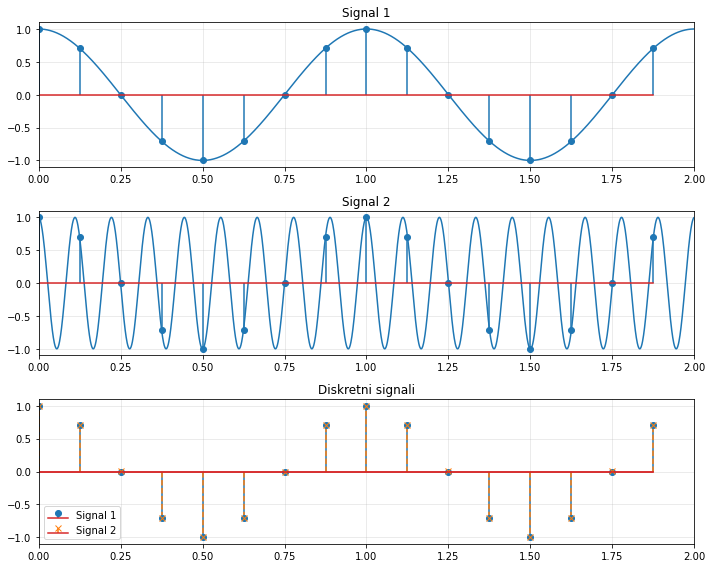

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fs = 8   
f1 = 1   
f2 = 9   

t_cont = np.linspace(0, 2, 2000)
t_samp = np.arange(0, 2, 1/fs)

sig1_cont = np.cos(2 * np.pi * f1 * t_cont)
sig2_cont = np.cos(2 * np.pi * f2 * t_cont)
sig1_samp = np.cos(2 * np.pi * f1 * t_samp)
sig2_samp = np.cos(2 * np.pi * f2 * t_samp)

fig, axes = plt.subplots(3, 1, figsize=(10, 8))

axes[0].plot(t_cont, sig1_cont)
axes[0].stem(t_samp, sig1_samp)
axes[0].set_title('Signal 1')

axes[1].plot(t_cont, sig2_cont)
axes[1].stem(t_samp, sig2_samp)
axes[1].set_title('Signal 2')

axes[2].stem(t_samp, sig1_samp, markerfmt='o', linefmt='C0-', label = "Signal 1")
axes[2].stem(t_samp, sig2_samp, markerfmt='x', linefmt='C1--', label = "Signal 2")
axes[2].set_title('Diskretni signali')
axes[2].legend()

for ax in axes:
    ax.set_xlim(0, 2)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


***

__Spektar signala__ predstavlja signal u frekvencijskoj domeni. Umjesto da gledamo kako signal izgleda u vremenu (vrijednost u nekom trenutku), spektar nam pokazuje koje frekvencije su prisutne u signalu i s kojim intenzitetom (amplitudom ili energijom). Matematički se dobiva primjenom Fourierove transformacije koja signal iz vremenske domene prevodi u frekvencijsku. Fourierovu transformaciju ćemo raditi kasnije. Za sada je važno nekoliko stvari:

Frekvencijska domena za kontinuirani signal sinusoide frekvencije $f_0$ daje simetrični spektar sa spektralnim komponentama u $\pm f_0$.
Diskretni signal dobiven uzorkovanjem tog diskretnog signala frekvencijom uzorkovanja $f_s$ također će dati simetrični spektar sa spektralnim komponentama u $\pm f_0$. 

Ali to uzorkovanje ima vrlo važnu posljedicu: spektar diskretnog signala je periodičan, odnosno ponavlja se svakih $f_s$ Hz. To znači da se cijeli frekvencijski sadržaj (spektar) signala beskonačno puta preslikava lijevo i desno svakih $f_s$ Hz, tj. pojavljuju se njegove kopije u frekvencijskom prostoru na $…,−2f_s,−f_s,0,f_s,2f_s,…$. 

Ako nije zadovoljen Nyquist-Shannonov teorem, susjedne kopije spektra počnu se preklapati, odnosno frekvencijske komponente iz jednog dijela spektra ulaze u drugi. Na primjer, ako je signal imao komponentu na $3 \text{ Hz}$, a uzorkujemo s $f_s=4 \text{ Hz}$ (što nije dovoljno jer je granica po Nyquist-Shannonovom teoremu $6 \text{ Hz}$), ta komponenta će se "preslikati" iz frekvencijskog prostora oko $f_s=4 \text{ Hz}$ i pojaviti kao $1 \text{ Hz}$ u osnovnom spektru diskretnog signala. 

Drugim riječima, kad signal ima visoku frekvenciju, ali se uzorkuje presporo, ta frekvencija se preslikava u neku nižu frekvenciju unutar osnovnog dijela spektra.
To znači da ćemo gledajući spektar diskretnog signala vidjeti frekvenciju nižu nego što zapravo jest. 

U nastavku je prikazan kontinuirani sinusni signal i njegov spektar. Ispod njega je njegov diskretni pandan i njegov spektar. Kod diskretnih signala se nakon Fourierove transformacije (kojom se dobiva spektar signala) spektralne komponente ponavljaju svakih $f_s$ frekvencija što je prikazano na zadnjem grafu.

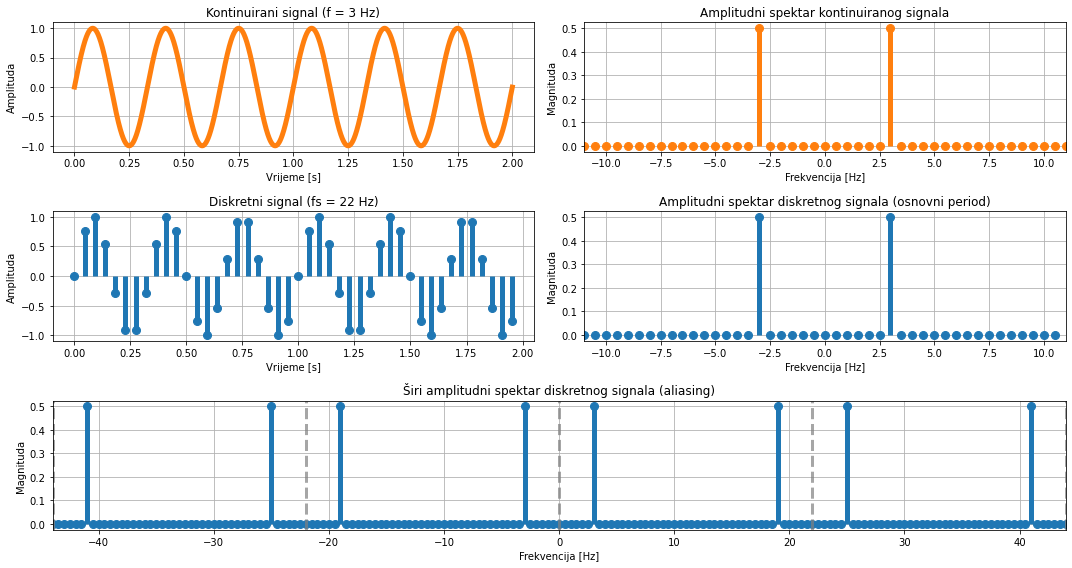

In [34]:
import numpy as np
import matplotlib.pyplot as plt

f_signal = 3       # Frekvencija signala [Hz]
fs = 22             # Frekvencija uzorkovanja [Hz]
duration = 2       # Trajanje signala [s]
fs_cont = 10000     # "Kontinuirani" uzorci

# ----------------- Kontinuirani signal -----------------
t_cont = np.arange(0, duration, 1/fs_cont)
x_cont = np.sin(2 * np.pi * f_signal * t_cont)

# FFT kontinuiranog signala
N_cont = len(x_cont)
X_cont = np.fft.fft(x_cont)
X_cont_mag = np.abs(X_cont) / N_cont
freqs_cont = np.fft.fftfreq(N_cont, 1/fs_cont)

# ----------------- Diskretni signal -----------------
t_disc = np.arange(0, duration, 1/fs)
x_disc = np.sin(2 * np.pi * f_signal * t_disc)

N = len(x_disc)
X = np.fft.fft(x_disc)
X_mag = np.abs(X) / N
freqs = np.fft.fftfreq(N, 1/fs)

# ----------------- Funkcija za preslikavanje -----------------
def repeat_spectrum_same_color(freqs, spectrum, fs, repeats=2):
    freq_all = []
    mag_all = []

    for k in range(-repeats, repeats + 1):
        shifted_freqs = freqs + k * fs
        freq_all.append(shifted_freqs)
        mag_all.append(spectrum)

    return np.concatenate(freq_all), np.concatenate(mag_all)

# ----------------- Priprema spektra -----------------
repeats = 2
freq_rep, mag_rep = repeat_spectrum_same_color(freqs, X_mag, fs, repeats)

# ----------------- Prikaz -----------------
plt.figure(figsize=(15, 8))

# 1. Kontinuirani signal u vremenu
plt.subplot(3, 2, 1)
plt.plot(t_cont, x_cont, color='tab:orange', linewidth=5)
plt.title(f'Kontinuirani signal (f = {f_signal} Hz)')
plt.xlabel('Vrijeme [s]')
plt.ylabel('Amplituda')
plt.grid(True)

# 2. Spektar kontinuiranog signala
plt.subplot(3, 2, 2)
markerline, stemlines, _ = plt.stem(freqs_cont, X_cont_mag, linefmt='b-', markerfmt='bo', basefmt=' ', use_line_collection=True)
plt.setp(stemlines, color='tab:orange', linewidth=5)
plt.setp(markerline, color='tab:orange', markersize=8)
plt.xlim(-11, 11)
plt.title('Amplitudni spektar kontinuiranog signala')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Magnituda')
plt.grid(True)

# 3. Diskretni signal u vremenu
plt.subplot(3, 2, 3)
markerline, stemlines, _ = plt.stem(t_disc, x_disc, linefmt='k-', markerfmt='ko', basefmt=' ', use_line_collection=True)
plt.setp(stemlines, color='tab:blue', linewidth=5)
plt.setp(markerline, color='tab:blue', markersize=8)
plt.title(f'Diskretni signal (fs = {fs} Hz)')
plt.xlabel('Vrijeme [s]')
plt.ylabel('Amplituda')
plt.grid(True)

# 4. Spektar diskretnog signala (osnovni period)
plt.subplot(3, 2, 4)
markerline, stemlines, _ = plt.stem(freqs, X_mag, basefmt=' ')
plt.setp(stemlines, color='tab:blue', linewidth=5)
plt.setp(markerline, color='tab:blue', markersize=8)
plt.title('Amplitudni spektar diskretnog signala (osnovni period)')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Magnituda')
plt.grid(True)
plt.xlim(-fs/2, fs/2)

# 5. Preslikani spektar (aliasing)
plt.subplot(3, 1, 3)
for f, m in zip(freq_rep, mag_rep):
    markerline, stemlines, _ = plt.stem([f], [m], basefmt=' ')
    plt.setp(stemlines, color='tab:blue', linewidth=5)
    plt.setp(markerline, color='tab:blue', markersize=8)

plt.title('Širi amplitudni spektar diskretnog signala (aliasing)')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Magnituda')
plt.grid(True)
plt.xlim(-2*fs, 2*fs)

# Oznake višekratnika f_s
for i in range(-2, 3):
    plt.axvline(i * fs, color='gray', linestyle='--', linewidth=3, alpha=0.7)

plt.tight_layout()
plt.show()


U sljedećem programu kreiran je signal koji se sastoji od dvije sinusne komponente različitih frekvencija. Ako koristimo frekvenciju uzorkovanja koja zadovoljava Nyquist–Shannonov teorem, u amplitudnom spektru uzorkovanog signala jasno se vide obje frekvencije na ispravnim pozicijama (prikazan je samo pozitivni dio spektra).

Ako se frekvencija uzorkovanja smanji ispod granice propisane teoremom, u spektru se pojavljuje frekvencijska komponenta na pogrešnom mjestu. To je posljedica aliasinga, odnosno preklapanja spektralnih kopija signala.

U ovom konkretnom slučaju signal se sastoji od frekvencija $f_1 = 1\,\text{Hz}$ i $f_2 = 7\,\text{Hz}$. 
Ako postavimo frekvenciju uzorkovanja $f_s = 10\,\text{Hz}$, oko te frekvencije u spektru se pojavljuju kopije spektra. 
Tada nastaju spektralne komponente na frekvencijama **3, 9, 11 i 17 Hz**, koje odgovaraju vrijednostima 
$f_s - f_2$, $f_s - f_1$, $f_s + f_1$ i $f_s + f_2$.

Budući da se kod diskretne Fourierove transformacije obično promatra samo raspon frekvencija 
$0 \le f \le f_s/2$, u ovom slučaju u spektru će biti vidljive samo komponente 
na **1 Hz** i **3 Hz**. Komponenta na 1 Hz odgovara stvarnoj frekvenciji signala, dok je komponenta na 
3 Hz rezultat **aliasinga** frekvencije od 7 Hz. Zbog toga rekonstruirani signal više ne odgovara 
originalnom signalu.

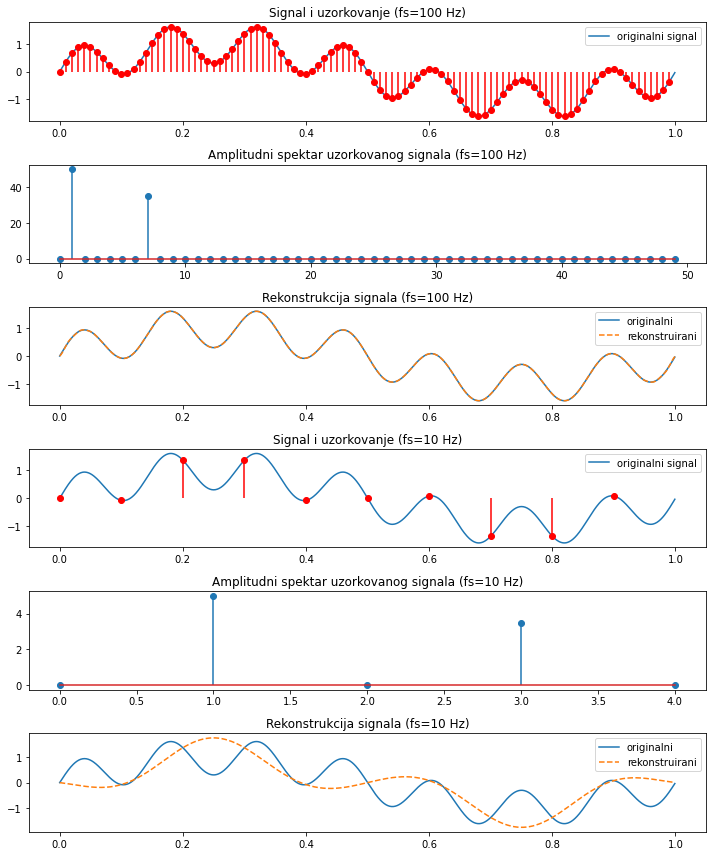

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs_cont = 1000
t = np.arange(0, 1, 1/fs_cont)

f1 = 1   
f2 = 7   
x = np.sin(2*np.pi*f1*t) + 0.7*np.sin(2*np.pi*f2*t)

fs = 100  
ts = np.arange(0, 1, 1/fs)
xs = np.sin(2*np.pi*f1*ts) + 0.7*np.sin(2*np.pi*f2*ts)

N = len(xs)
X = np.fft.fft(xs)
freq = np.fft.fftfreq(N, 1/fs)

# rekonstrukcija 
t_rec = np.arange(0, 1, 1/fs_cont)
x_rec = np.zeros_like(t_rec)

for n in range(len(xs)):
    x_rec += xs[n] * np.sinc((t_rec - ts[n]) * fs)
    
    
#################################    
# manja frekvencija uzorkovanja

fs2 = 10
ts2 = np.arange(0, 1, 1/fs2)
xs2 = np.sin(2*np.pi*f1*ts2) + 0.7*np.sin(2*np.pi*f2*ts2)

N2 = len(xs2)
X2 = np.fft.fft(xs2)
freq2 = np.fft.fftfreq(N2, 1/fs2)

t_rec2 = np.arange(0, 1, 1/fs_cont)
x_rec2 = np.zeros_like(t_rec2)

for n in range(len(xs2)):
    x_rec2 += xs2[n] * np.sinc((t_rec2 - ts2[n]) * fs2)
    

#prikaz

plt.figure(figsize=(10,12))

plt.subplot(6,1,1)
plt.plot(t, x, label="originalni signal")
plt.stem(ts, xs, linefmt='r-', markerfmt='ro', basefmt=" ")
plt.title("Signal i uzorkovanje (fs=100 Hz)")
plt.legend()

plt.subplot(6,1,2)
plt.stem(freq[:N//2], np.abs(X[:N//2]))
plt.title("Amplitudni spektar uzorkovanog signala (fs=100 Hz)")

plt.subplot(6,1,3)
plt.plot(t, x, label="originalni")
plt.plot(t_rec, x_rec, '--', label="rekonstruirani")
plt.title("Rekonstrukcija signala (fs=100 Hz)")
plt.legend()

plt.subplot(6,1,4)
plt.plot(t, x, label="originalni signal")
plt.stem(ts2, xs2, linefmt='r-', markerfmt='ro', basefmt=" ")
plt.title("Signal i uzorkovanje (fs=10 Hz)")
plt.legend()

plt.subplot(6,1,5)
plt.stem(freq2[:N2//2], np.abs(X2[:N2//2]))
plt.title("Amplitudni spektar uzorkovanog signala (fs=10 Hz)")

plt.subplot(6,1,6)
plt.plot(t, x, label="originalni")
plt.plot(t_rec2, x_rec2, '--', label="rekonstruirani")
plt.title("Rekonstrukcija signala (fs=10 Hz)")
plt.legend()

plt.tight_layout()
plt.show()

***

__Aliasing kod audio signala__

Prosječan čovjek čuje od 20 Hz do 20.000 Hz (20 kHz).  
Kod većine odraslih osoba gornja granica padne na oko 15–18 kHz, ovisno o dobi i izloženosti buci.

- 20–60 Hz	    Vrlo niske frekvencije (npr. subwooferi)
- 60–250 Hz	    Bas (bubnjevi, muški glasovi)
- 250–2000 Hz	Srednji tonovi (govor, većina instrumenata)
- 2000–5000 Hz	Visoki tonovi, oštrina, artikulacija govora
- 5000–20000 Hz	Vrlo visoki tonovi (npr. činela, s, š)

Zato moderni audio standardi (CD, streaming) koriste frekvenciju uzorkovanja 44100 Hz, jer mogu snimiti sve do ≈22 kHz, što pokriva cijeli ljudski raspon.


U donjem primjeru aliasing se javlja za frekvenciju uzorkovanja 4000 Hz jer prvi i posljednji audio zapis predstavljaju isti ton, iako su njihove frekvencije različite (220 Hz i 4220 Hz).

In [1]:
import numpy as np
from IPython.display import display, Audio

fs = 4000 # Sampling at 4KHz
f0_original = 220 # A pure tone at 220Hz
f0_aliased =  4220 # f0_original + 1*fs # k=2
duration = 2
N = int(duration * fs) # Number of samples
n = np.arange(N) # Generate the sample positions

# Construct the signals
x_original = np.cos(2 * np.pi * f0_original * n / fs)
x_aliased = np.cos(2 * np.pi * f0_aliased * n / fs)
x_250 = np.cos(2 * np.pi * 250 * n / fs)

# Let's hear them both
print("fs = {} Hz, f0 = {} Hz".format(fs, f0_original))
display(Audio(data=x_original, rate=fs))
print("fs = {} Hz, f0 = 250 Hz".format(fs, f0_aliased))
display(Audio(data=x_250, rate=fs))
print("fs = {} Hz, f0 = {} Hz".format(fs, f0_aliased))
display(Audio(data=x_aliased, rate=fs))

fs = 4000 Hz, f0 = 220 Hz


fs = 4000 Hz, f0 = 250 Hz


fs = 4000 Hz, f0 = 4220 Hz


__Zašto je frekvencija uzorkovanja audiosignala baš 44100 Hz?__ Ta vrijednost potječe iz ranih dana digitalnog snimanja. Krajem 1970-ih i početkom 1980-ih audiosignal se snimao na video kasete pomoću PCM adaptera jer tada još nisu postojali uređaji namijenjeni digitalnoj pohrani zvuka. Ideja je bila kodirati digitalne audio uzorke unutar linija videosignala kako bi se mogli snimiti standardnim videorekorderom. Kako bi sustav bio kompatibilan s oba televizijska standarda tog razdoblja (PAL i NTSC), odlučeno je da svaka video linija nosi 3 audio uzorka. Razlog za taj izbor može se razumjeti iz strukture PAL i NTSC sustava.

PAL je imao 294 aktivne linije po poluslici (jedna slika se prikazivala kao dvije poluslike isprepletenih linija) i 50 poluslika u sekundi (50 Hz), a NTSC 245 linija po poluslici i 60 poluslika u sekundi (60 Kz). To znači da je broj linija dostupnih za prijenos uzoraka u sekundi bio:

$294 \cdot 50 = 14700$

$245 \cdot 60 = 14700$

Odabrano je imati 3 uzorka po liniji u oba slučaja kako bi frekvencija uzorkovanja bila iznad željenih 40 kHz. To znači da je konačna frekvencija uzorkovanja audiosignala bila

$f_s = 14700 \cdot 3 = 44100 \text{ Hz}$

Na taj način dobivena je frekvencija uzorkovanja koja je kompatibilna s oba televizijska standarda i omogućuje reprodukciju frekvencija do
$f_{max} = \frac{f_s}{2} = 22050 \text{ Hz}$ što pokriva cijeli čujni raspon čovjeka.

***

Danas postoji nekoliko standardnih frekvencija uzorkovanja audiosignala. Frekvencija **44.1 kHz** standard je za glazbu i audio CD te se koristi u većini streaming servisa jer pokriva cijeli čujni spektar. Frekvencija **48 kHz** najčešća je u video produkciji, televiziji i filmu i koristi se u kamerama i broadcast sustavima jer je pogodna za sinkronizaciju s video signalima. U profesionalnoj produkciji često se koriste i više frekvencije poput **96 kHz** i **192 kHz**, koje daju više mogućnosti za digitalnu obradu signala poput preciznijeg filtriranja, smanjenja aliasinga i vjernijeg snimanja visokih frekvencija.

U praksi se često snima na 48 kHz ili 96 kHz, a zatim se signal po potrebi spušta na nižu frekvenciju za distribuciju.